### Current work
- cross-layer resource management for ISAC systems, beam management
- The BS acts as the agent. It updates the beam allocation according to the buffer situation as well as the previous beam quality
- It uses OFDM waveform to serve multiple users
- When there is a packet to be transmitted to a user, the user is *communication user*, otherwise a *sensing user*. 
- The agent wants to minimize the latency of the packets (communication-prioritized) and minimize the sensing performance of the sensing users. 


### Summary of changes 13.06 - 27.06
- Changed the reward of sensing performance: from an indicator function to logarithm function. So, a smaller estimation error gives a higher reward.

- Training period: the starting points of users are fixed. As such, the trajectories of users are fixed to a set. Less randomness, better convergence.

- Previously, I found that PPO's estimation performance is worse compared to the benchmark. It's because I combined two users estimation performance together. I think, the estimation performance should be analyzed for each user. See Sensing Performance below. 

    - I had a hypothesis that user 0's sensing performance is worse compared to the benchmark because it has a higher communication need. So, the agent focuses more on user 0's communication. On the other hand, user 1 has a better sensing performance compared to the benchmark. 
    However, the recent tests are against the hypothesis.

### Feedback on 27.06
1. Try the trajectories where the users have a similar SNRs. 

2. Train the policy with a lower transmit power. The current transmit power is too high for some user locations such that lots of beams satisfy its SINR requirement.

3. Change a metric for showing sensing performance. CDF of error --> probability of (error < threshold)

 
### Changed the data traffic assumptions

- Buffer for $U$ users are $[B_1, \cdots, B_U]$, each with a different finite buffer size. 
- First-in first-out principle.
- The latency constraints, deadlines, of users are $T_1, \cdots, T_U$.
- The arrival probability of packets follow Binomial distribution with different arrival rates $P_{d1}, \cdots, P_{dU}$. 
- A packet is of size 1. 
- Each packet is associated with a waiting time. We define $\delta_1, \cdots, \delta_U$ as the waiting time of the packets that is transmitted at the current TTI. 

- Packet drop:
    - Expired packet $drop_{l}$: a packet's waiting time is longer than their latency constraints $T$.

    - Buffer overload $drop_{o}$: a user's buffer is full and there is new packet coming.



#### Objective function
This paper considers the cross-layer resource management for ISAC. Incorporating the buffer statues, the BS allocates beams from the codebook for different users. 

At any given TTI, the agent has obtained a historical environment information from the received echo, which implies the quality of the allocated beams. It uses these historical measurements to decide the next beams in an intelligent manner. The goal of the BS is to minimize the transmission latency and the normalized estimation errors.

$$
\begin{align}
\underset{\mathbf{F}}{\text{minimize}}&~~ \sum_{u=1}^{U} \delta_u^{(t)} + \epsilon_v + \epsilon_d \\
\text{subject to}&~~ \delta_u^{(t)} = \begin{cases}&\delta_u^{(t-1)}+ \mathbb{1}_{\log(1+\gamma_u^{(t)}) < R_{th}} , B_u \neq 0 \\ &0, B_u=0 \end{cases} \\
                &~~  \epsilon_v^{(t)} = |\hat{v}^{(t)} - {v}^{(t)}| \\
                &~~ \epsilon_d^{(t)} = |\hat{d}^{(t)} - {d}^{(t)}| 
\end{align}
$$
$\delta_u$ denotes the latency of the packet that is to be transmitted in each user's buffer, i.e., the packet has the longest latency. 

The estimation performance of range and speed are affected by the number of subcarriers, the number of OFDM symbols respectively.
Therefore, the normalized error are defined with respect to these bins.


### Actions:
To decrease the action space dimension, we reverted the action space to be as the conference version. 

- a = 0, the beams stay the same
- a = 1, select the best beam from the previously-allocated multiple beams
- a = 2, sweep the beams to the left, select the 3 adjacent beams on the left of the previously-allocated beams 
- a = 3, sweep the beams to the right, select the 3 adjacent beams on the right of the previously-allocated beams 

*Note*: Beams are not reused. For a user, if the allocated beams are already used, the agent searches the closest unused beam.  


#### Reward calculation
The reward is calculated as 
- Transmission reward: the earlier the transmission, the higher the reward
$\sum_{u=1}^{U} T_u - \delta_u$
    - If there is no packet transmitted by a user, its transmission reward is 0.
    - If a packet's waiting time is longer than the deadline, the reward is less than 0

- **Sensing reward**: 
    1. The sensing performance should be as low as possible.
    It was an indicator function. Now it is changed to a logarithm function: $\log_{1/3} \epsilon_r, \quad \log_{1/3} \epsilon_v $. 

$reward = \sum_{u=1}^{U} (T_u - \delta_u) + \sum_{u=1}^U \log_{1/3} \epsilon_r + \log_{1/3} \epsilon_v $ 

**Benchmark**
- Estimated AoD: The BS estimates the AoDs using MUSIC algorithm based on the reflected echoes. 
Then, the BS best beams to users according to these estimated AoDs.

- Random: One beam is randomly allocated to a user.

**Comparison of reward**
The benchmark of Estimated AoDs is even worse than the begining of the PPO training. 
- Reason: Estimated AoD method only allocates one beam to a user, this will often lead to a bad estimation performance, which is captured by the reward calculation.

---

#### Reward

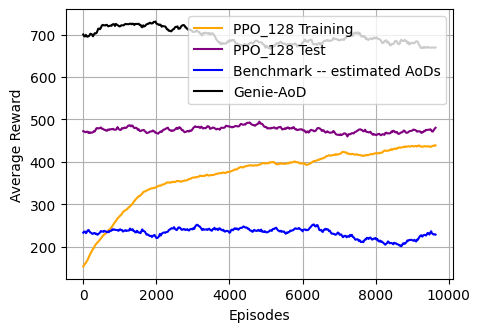

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
log_dir = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/'
monitor_file = log_dir + "monitor_0.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=1)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()

fd_trained = log_dir +'trained_09/'
trained_reward = pd.read_csv(fd_trained + 'reward.csv', skiprows=0)
tr = trained_reward['Reward'].rolling(window = 100).mean()

fd_genie = log_dir +'genie_09/'
genie_reward = pd.read_csv(fd_genie + 'reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()


fd_estimated = log_dir +'estimated_09/'
benchmark_reward = pd.read_csv(fd_estimated + 'reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())

selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]

# monitor_file_reusebeams = 'RL_mimo_ofdm/PPO_2ue16Nt_newMem3/monitor_0.csv'
# monitor_data_reusebeams = pd.read_csv(monitor_file_reusebeams, skiprows=0)
# window_size_reusebeams = 1000
# moving_average_reusebeams = monitor_data_reusebeams['r'].rolling(window=window_size_reusebeams).mean().dropna()
# selected_values_reusebeams = moving_average_reusebeams[::len(moving_average_reusebeams)//br_length][:(br_length)]

# monitor_file_test = 'RL_mimo_ofdm/PPO_2ue16Nt_newMem3/trained/reward.csv'
# monitor_data_test = pd.read_csv(monitor_file_test, skiprows=0)
# tr2 = monitor_data_test['Reward'].rolling(window = 100).mean()

# fd_random = log_dir +'random/'
# random_reward = pd.read_csv(fd_random + 'reward.csv', skiprows=0)
# rr = random_reward['Reward'].rolling(window = 100).mean()


fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)
ax.plot(np.linspace(0, len(moving_average), br_length), selected_values.dropna(), label='PPO_128 Training', color='orange')
# ax.plot(np.linspace(0, len(moving_average_reusebeams), br_length), selected_values_reusebeams.dropna(), label='PPO_128_new_statespace', color='green')
ax.plot(np.linspace(0, len(moving_average), br_length), tr.dropna(), label='PPO_128 Test', color='purple')
ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')
# ax.plot(np.linspace(0, len(moving_average), br_length), rr.dropna(), label='Random', color='red')
# ax.plot(np.linspace(0, len(moving_average), br_length), tr2.dropna(), label='PPO_128_new_statespace Test Test', color='red')

ax.legend(loc='upper right')
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

**Communication -- Latency**

The following figure evaluates the probability of waiting time for a **transmitted** packet for different methods.

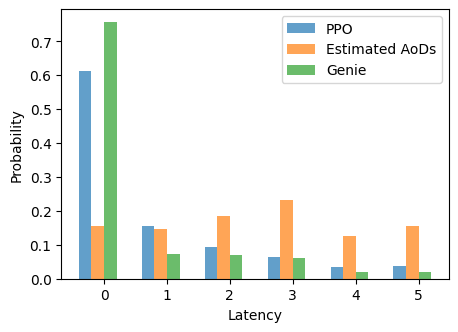

In [11]:
import matplotlib.pyplot as plt
import itertools
import pandas as pd

def load_latency(log_dir, filename):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    data1 = list(itertools.chain(*data.values))
    data2 = [x for x in data1 if x != -1]
    return data2

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')
# latency_r = load_latency(fd_random , 'latency.csv')


#
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax2 = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax2.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark, bins_benchmark, patches_benchmark = ax2.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax2.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')
# counts_random, bins_random, patches_random = ax2.hist(latency_random, bins=range(7), density=True, alpha=0.7, label='Random')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])

ax2.cla()  # Clear the previous plot
ax2.bar(bin_centers - 0.3, counts_trained, width=0.2, align='center', alpha=0.7, label='PPO')
ax2.bar(bin_centers - 0.1, counts_benchmark, width=0.2, align='center', alpha=0.7, label='Estimated AoDs')
ax2.bar(bin_centers+0.1, counts_genie, width=0.2, align='center', alpha=0.7, label='Genie')
# ax2.bar(bin_centers+0.3, counts_random, width=0.2, align='center', alpha=0.7, label='Random')
# ax2.bar(bin_centers + 0.3, counts_reusebeams, width=0.2, align='center', alpha=0.7, label='PPO Reuse Beams')

ax2.set_xticks(bin_centers)

ax2.set_xticks(bin_centers)
ax2.set_xticklabels(range(6))
ax2.set_xlabel('Latency')
ax2.set_ylabel('Probability')
ax2.legend()


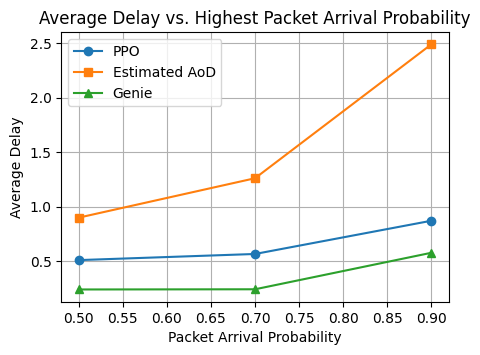

In [12]:
fd_trained_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh/trained_05/'
fd_estimated_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh/estimated_05/'
fd_genie_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh/genie_05/'
fd_trained_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh/trained_07/'
fd_estimated_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh/estimated_07/'
fd_genie_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh/genie_07/'

latency_trained_09 = load_latency(fd_trained, 'latency.csv')
latency_benchmark_09 = load_latency(fd_estimated, 'latency.csv')
latency_genie_09 = load_latency(fd_genie, 'latency.csv')

latency_trained_05 = load_latency(fd_trained_05, 'latency.csv')
latency_benchmark_05 = load_latency(fd_estimated_05, 'latency.csv')
latency_genie_05 = load_latency(fd_genie_05, 'latency.csv')

latency_trained_07 = load_latency(fd_trained_07, 'latency.csv')
latency_benchmark_07 = load_latency(fd_estimated_07, 'latency.csv')
latency_genie_07 = load_latency(fd_genie_07, 'latency.csv')

counts_trained = np.zeros([6,3])
counts_benchmark = np.zeros([6,3])
counts_genie = np.zeros([6,3])

counts_trained[:,2], _, _ = ax2.hist(latency_trained_09, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,2], _, _ = ax2.hist(latency_benchmark_09, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,2], _, _ = ax2.hist(latency_genie_09, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,0], _, _ = ax2.hist(latency_trained_05, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,0], _, _ = ax2.hist(latency_benchmark_05, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,0], _, _ = ax2.hist(latency_genie_05, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,1], _, _ = ax2.hist(latency_trained_07, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,1], _, _ = ax2.hist(latency_benchmark_07, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,1], _, _ = ax2.hist(latency_genie_07, bins=range(7), density=True, alpha=0.7, label='Genie')
# Calculate average delays
ave_delay_trained = np.dot(range(6), counts_trained)
ave_delay_estimated = np.dot(range(6), counts_benchmark)
ave_delay_genie = np.dot(range(6), counts_genie)

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)
arrival_prob = [0.5, 0.7, 0.9]

ax.plot(arrival_prob, ave_delay_trained, marker='o', label='PPO')
ax.plot(arrival_prob, ave_delay_estimated, marker='s', label='Estimated AoD')
ax.plot(arrival_prob, ave_delay_genie, marker='^', label='Genie')

ax.set_xlabel('Packet Arrival Probability')
ax.set_ylabel('Average Delay')
ax.set_title('Average Delay vs. Highest Packet Arrival Probability')
ax.legend()
ax.grid(True)
plt.show()


The above figure shows the averaged delay of packets as a function of packet arrival probability.
When the packet arrival probability is higher, the gain of PPO is bigger. This implies that the cross-layer resource management is helpful. 

**Communication -- spectral efficiency**

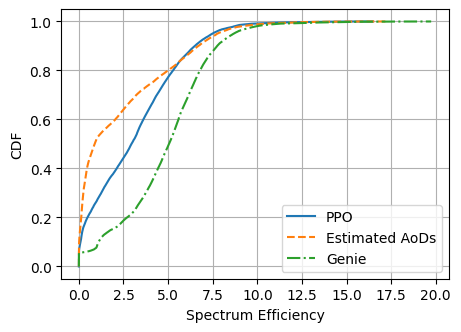

In [13]:
se_trained = pd.read_csv(fd_trained + 'SE.csv', skiprows=0)
se_benchmark = pd.read_csv(fd_estimated + 'SE.csv', skiprows=0)
se_genie = pd.read_csv(fd_genie+'SE.csv', skiprows=0)
# se_random = pd.read_csv(fd_random + 'SE.csv', skiprows=0)

spectrum_efficiency_trained = list(itertools.chain(*se_trained.values))
spectrum_efficiency_benchmark = list(itertools.chain(*se_benchmark.values))
spectrum_efficiency_genie = list(itertools.chain(*se_genie.values))
# spectrum_efficiency_random = list(itertools.chain(*se_random.values))

figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()
se_cdf = np.sort(spectrum_efficiency_trained)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '-', label='PPO')

se_cdf = np.sort(spectrum_efficiency_benchmark)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '--', label='Estimated AoDs')

se_cdf = np.sort(spectrum_efficiency_genie)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '-.', label='Genie')

# se_cdf = np.sort(spectrum_efficiency_random)
# yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
# ax.plot(se_cdf, yvals, ':', label='Random')

ax.set_xlabel('Spectrum Efficiency')
ax.set_ylabel('CDF')
ax.legend()
ax.grid()

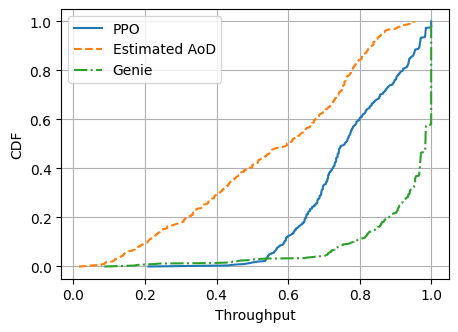

In [14]:
def cdf_gen(log_dir, filename, item):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    cdf = np.sort(data[item])
    yvals = np.arange(len(cdf))/float(len(cdf)-1)
    return cdf, yvals

#### Throughput CDF ####

figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

thp_cdf, yvals = cdf_gen(fd_trained, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-', label='PPO')

thp_cdf, yvals = cdf_gen(fd_estimated, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '--', label='Estimated AoD')

thp_cdf, yvals = cdf_gen(fd_genie, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-.', label='Genie')

# thp_cdf, yvals = cdf_gen(fd_new, 'throughput.csv', 'Throughput')
# ax.plot(thp_cdf, yvals, '-.', label='PPO new State Space Test')

ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

---

#### Sensing -- Estimation performance


For estimation of range and speed (the following two figures), compared to the benchmark, different users can perform differently. 

In [15]:
# ######################################## CDF of estimation error ####
# N_UTs = 2
# # range estimation
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
# er_r = pd.read_csv(fd_random + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1)

# figure_handle = plt.figure()
# ax3 = figure_handle.add_subplot()
er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
# er_random = np.array(er_r)
er_genie = np.array(er_g)
# colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
# linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
# labels = ['User 0', 'User 1']

# for idx in range(N_UTs):    
#     temp = er_benchmark[:,idx]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax3.plot(er_cdf, yvals, linestyle=linestyles['Estimated AoD'], color=colors[idx], label=f'Estimated AoD {labels[idx]}')

#     temp = er_trained[:,idx]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax3.plot(er_cdf, yvals, linestyle=linestyles['PPO'], color=colors[idx], label=f'PPO {labels[idx]}')

#     # temp = er_genie[:,idx]
#     # er_cdf = np.sort(temp)
#     # yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     # ax3.plot(er_cdf, yvals, linestyle=linestyles['Genie'], color=colors[idx], label=f'Genie {labels[idx]}')


# ax3.set_xlabel('Normalized Error of Range Estimation')
# ax3.set_ylabel('CDF')
# ax3.legend()
# plt.show()

# ################################### CDF of speed estimation error
ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
# ev_r = pd.read_csv(fd_random + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1)

ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
# ev_random = np.array(ev_r)
ev_genie = np.array(ev_g)

# figure_handle = plt.figure()
# ax4 = figure_handle.add_subplot()

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
labels = ['User 0', 'User 1']

# for idx in range(N_UTs):    
#     temp = ev_benchmark[:,idx]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax4.plot(er_cdf, yvals, linestyle=linestyles['Estimated AoD'], color=colors[idx], label=f'Estimated AoD {labels[idx]}')

#     temp = ev_trained[:,idx]
#     er_cdf = np.sort(temp)
#     yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     ax4.plot(er_cdf, yvals, linestyle=linestyles['PPO'], color=colors[idx], label=f'PPO {labels[idx]}')

#     # temp = ev_genie[:,idx]
#     # er_cdf = np.sort(temp)
#     # yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
#     # ax4.plot(er_cdf, yvals, linestyle=linestyles['Genie'], color=colors[idx], label=f'Genie {labels[idx]}')
    
# ax4.set_xlabel('Normalized Error of Speed Estimation')
# ax4.set_ylabel('CDF')
# ax4.legend()
# plt.show()

# # Probability of error lower than 0.5 for each user and method

# def prob_error_below_threshold(data, threshold=0.5):
#     return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]

# # Range estimation
# prob_range_trained = prob_error_below_threshold(er_trained, 0.5)
# prob_range_benchmark = prob_error_below_threshold(er_benchmark, 0.5)
# prob_range_genie = prob_error_below_threshold(er_genie, 0.5)

# # Speed estimation
# prob_speed_trained = prob_error_below_threshold(ev_trained, 0.5)
# prob_speed_benchmark = prob_error_below_threshold(ev_benchmark, 0.5)
# prob_speed_genie = prob_error_below_threshold(ev_genie, 0.5)

# print("Probability of range error < 0.5")
# for idx, label in enumerate(labels):
#     print(f"{label}: PPO={prob_range_trained[idx]:.3f}, Estimated AoD={prob_range_benchmark[idx]:.3f}, Genie={prob_range_genie[idx]:.3f}")

# print("\nProbability of speed error < 0.5")
# for idx, label in enumerate(labels):
#     print(f"{label}: PPO={prob_speed_trained[idx]:.3f}, Estimated AoD={prob_speed_benchmark[idx]:.3f}, Genie={prob_speed_genie[idx]:.3f}")



| User   | Arrival Probability | Packet Deadline ($T_u$) | Buffer Size ($B_u$) |
|--------|--------------------|-------------------------|---------------------|
| User 0 | 0.9                |   6                     |     4             |
| User 1 | 0.7                 |   8                     |   5                |


In the experiment, User 0 is closer to the base station than User 1. The echo contains a stronger signal from User 0, which results in a more accurate estimation performance. 

- For blue and orange bars: 
    User 0 has more strict requirements on communication. 
    The trained agent prioritizes User 0 communication. So for user 0, the trained PPO has a worse estimation performance compared to the baseline estimated AoD method.

    For User 1 (orange curves), the trained agent achieves a better estimation performance compared to the baseline estimated AoD method.  

Hypothesis: sensing performance is associated with communication requirement.

- For green and red bars:
    User 1 has requires more communication. It is okay for user 1 to perform worse in sensing.

    However, User 0's sensing performance is also worse compared to the benchmark. 

    This is againt the hypothesis.

In [16]:
# Calculate probability of estimation error < th_prob for each user and method
# Count the number of times estimation error < th_prob for each user and method, and normalize by total number
# def prob_error_below_threshold(data, threshold=0.05):
    # return [(data[:, idx] < threshold).sum() / data.shape[0] for idx in range(data.shape[1])]
def prob_error_below_threshold(data, threshold=0.05):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]

ev_b1 = pd.read_csv(log_dir + 'estimated_bufferDiff_1/' + 'nmseV_allsteps.csv', skiprows=1)
ev_benchmark1 = np.array(ev_b)
th_prob = 0.2
prob_benchmark = prob_error_below_threshold(ev_benchmark, th_prob)
prob_trained0 = prob_error_below_threshold(ev_trained0, th_prob)
prob_trained1 = prob_error_below_threshold(ev_trained1, th_prob)

prob_benchmark1 = prob_error_below_threshold(ev_benchmark1, th_prob)
prob_genie = prob_error_below_threshold(ev_genie, th_prob)

x = np.arange(len(labels))
width = 0.1

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 2*width, prob_benchmark, width, label='Benchmark U0 CommunReq')
ax.bar(x - width, prob_trained0, width, label='PPO U0 CommunReq')
ax.bar(x , prob_benchmark1, width, label='Benchmark U1 CommunReq')
ax.bar(x + width, prob_trained1, width, label='PPO U1 CommunReq')
ax.bar(x + 2*width, prob_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(speed error < 0.3)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/estimated_bufferDiff_1/nmseV_allsteps.csv'

PPO's range estimation performance is better compared to the benchmark.

NameError: name 'x' is not defined

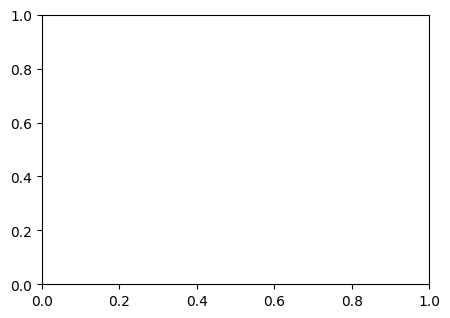

In [17]:
def prob_error_below_threshold(data, threshold=0.2):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]

# Calculate for range estimation error
prob_range_trained_02 = prob_error_below_threshold(er_trained, 0.2)
prob_range_benchmark_02 = prob_error_below_threshold(er_benchmark, 0.2)
prob_range_genie_02 = prob_error_below_threshold(er_genie, 0.2)

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - width, prob_range_benchmark_02, width, label='Benchmark')
ax.bar(x, prob_range_trained_02, width, label='PPO')
ax.bar(x + width, prob_range_genie_02, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(range error < 0.2)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


#### Evaluation instances

![[image.png|300]](attachment:image.png)  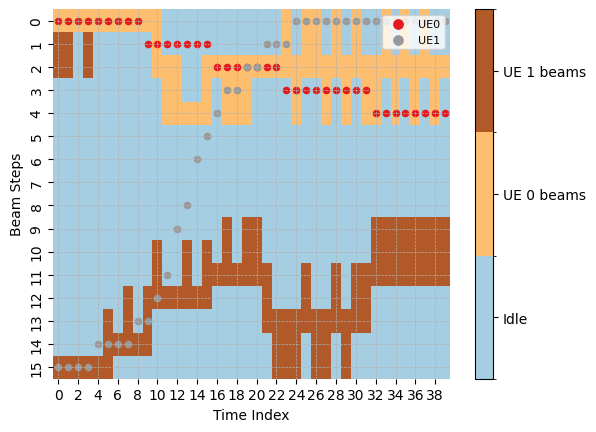

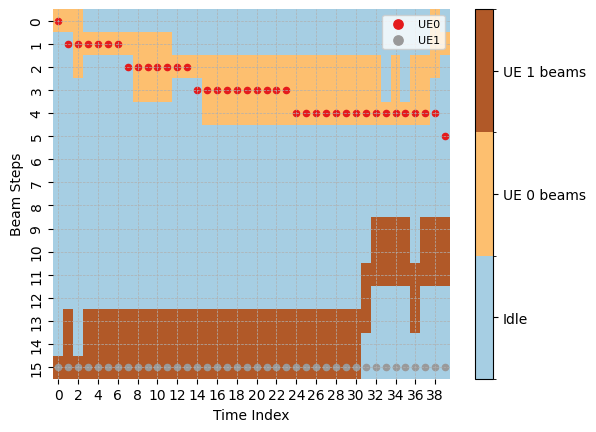 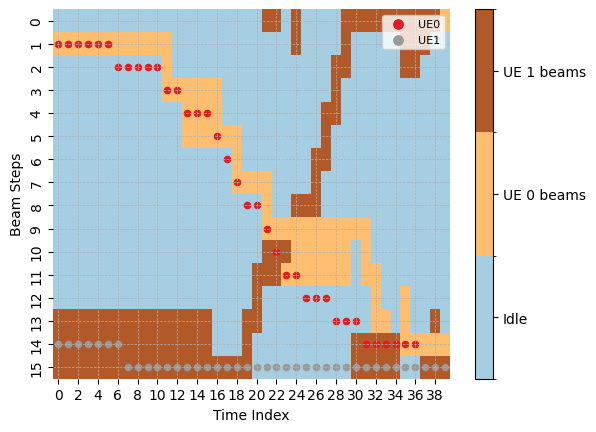


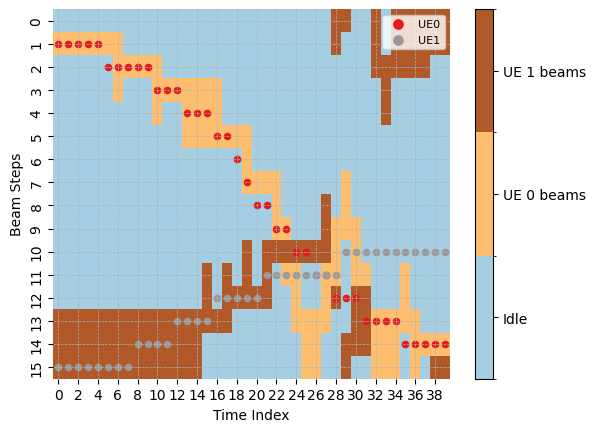